In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("msambare/fer2013")

print("Path to dataset files:", path)

/home/vizanca/AprentisageRobotique/FaceRecognition/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /home/vizanca/.cache/kagglehub/datasets/msambare/fer2013/versions/1


In [3]:
import os
import matplotlib.pyplot as plt

path = "/home/vizanca/.cache/kagglehub/datasets/msambare/fer2013/versions/1/train/"
folders = os.listdir(path) # List of folders in the train directory

import numpy as np

list_of_images = []
label_images = [] # (0: angry, 1: disgust, 2: fear, 3: happy, 4: sad, 5: surprise, 6: neutral)

for folder in range(len(folders)):
    folder_path = os.path.join(path, folders[folder])
    images = os.listdir(folder_path)
    for image in images:
        image_path = os.path.join(folder_path, image)
        img = plt.imread(image_path)
        list_of_images.append(img)
        label_images.append(folder) # Append the label corresponding to the folder

print("Number of images:", len(list_of_images))
print("Number of labels:", len(label_images))
print("Number of angry images:", label_images.count(0))
print("Number of disgust images:", label_images.count(1))
print("Number of fear images:", label_images.count(2))
print("Number of happy images:", label_images.count(3))
print("Number of sad images:", label_images.count(4))
print("Number of surprise images:", label_images.count(5))
print("Number of neutral images:", label_images.count(6))


Number of images: 28709
Number of labels: 28709
Number of angry images: 3171
Number of disgust images: 4965
Number of fear images: 436
Number of happy images: 4830
Number of sad images: 4097
Number of surprise images: 3995
Number of neutral images: 7215


In [4]:
# usar lbp para extrair características das imagens e treinar um classificador de aprendizado de máquina para reconhecer emoções faciais.
imgs_np = np.array(list_of_images)
lable_np = np.array(label_images)

from matplotlib.colors import ListedColormap
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import (KNeighborsClassifier,
                               NeighborhoodComponentsAnalysis)
from sklearn.pipeline import Pipeline
X_train, X_test, y_train, y_test = train_test_split(imgs_np, lable_np, stratify=lable_np, test_size=0.7, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8612, 48, 48)
X_test shape: (20097, 48, 48)
y_train shape: (8612,)
y_test shape: (20097,)


In [5]:
# LBP calculation
from skimage.feature import local_binary_pattern

numpoints_lbp = 25
radius_lbp = 5
lbp_method = 'uniform'

X_train_lbp = np.zeros(X_train.shape)
for i in range(X_train.shape[0]):
    X_train_lbp[i,:,:] = local_binary_pattern(X_train[i,:,:], numpoints_lbp, radius_lbp, method=lbp_method)

print(X_train_lbp.shape)


(8612, 48, 48)


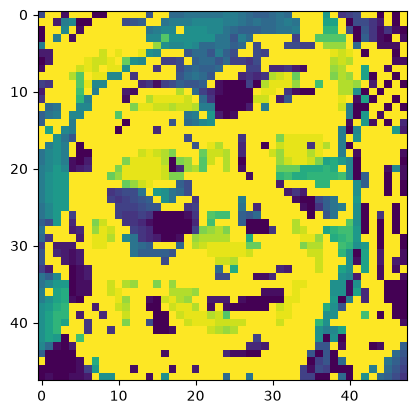

In [6]:
plt.imshow(X_train_lbp[5,:,:])
plt.show()

In [9]:
# partition image into 4*4 regions 
# then calculate 16 historgram , 10 bins in historgramme for each region (10 * 16)
N = 4
n_bins = 10

X_lbp_hist_16_counts = np.zeros([X_train.shape[0], N*N , n_bins ])
X_lbp_hist_16_bins = np.zeros([X_train.shape[0], N*N , n_bins + 1 ])
X_lbp_hist_16 = np.zeros([X_train.shape[0], N*N , n_bins ])
for i in range(X_train.shape[0]):
    X_lbp = X_train_lbp[i,:,:]
    for j in range(X_lbp_hist_16.shape[1]) :
        ii = np.floor(j/N)
        jj = j%N
        h1 = int( ii*(48/N) )
        h2 = int( (ii+1)*(48/N) )
        w1 = int( jj*(48/N) )
        w2 = int( (jj+1)*(48/N) )
        counts, bins = np.histogram(X_lbp[ h1 : h2 ,  w1 : w2].flatten(), bins=n_bins, range=(0,9))
        X_lbp_hist_16_counts[i,j,:] = counts
        X_lbp_hist_16_bins[i,j,:] = bins

print(X_lbp_hist_16_bins.shape)

print(X_lbp_hist_16_counts.shape)

(8612, 16, 11)
(8612, 16, 10)


In [10]:
# Function calculate the 16 histogrammes for one image


def NN_histogram(img_lbp,N,n_bins):
    X_lbp_histNN_counts = np.zeros([N*N , n_bins ])
    X_lbp_histNN_bins = np.zeros([N*N , n_bins+1 ])
    for j in range(N*N) :
        ii = np.floor(j/N)
        jj = j%N
        h1 = int( ii*(48/N) )
        h2 = int( (ii+1)*(48/N) )
        w1 = int( jj*(48/N) )
        w2 = int( (jj+1)*(48/N) )
        counts, bins = np.histogram(img_lbp[ h1 : h2 ,  w1 : w2].flatten(), bins=n_bins, range=(0,9))
        X_lbp_histNN_counts[j,:] = counts
        X_lbp_histNN_bins[j,:] = bins
    return X_lbp_histNN_counts , X_lbp_histNN_bins

(10,)


(array([1., 0., 0., 0., 0., 2., 3., 2., 0., 0.]),
 array([0. , 0.9, 1.8, 2.7, 3.6, 4.5, 5.4, 6.3, 7.2, 8.1, 9. ]),
 <BarContainer object of 10 artists>)

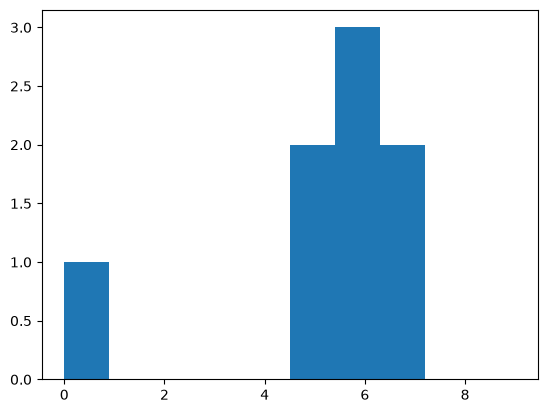

In [11]:
# example usage NN_histogram(img_lbp,N,n_bins):
N = 4
n_bins = 10
X_lbp = X_train_lbp[2,:,:]

counts, bins = NN_histogram(X_lbp,N,n_bins)

region = 5
X_lbp_histNN_counts = counts[region,:]
X_lbp_histNN_bins = bins[region,:]
print(X_lbp_histNN_counts.shape)

plt.hist(X_lbp_histNN_bins[:-1], X_lbp_histNN_bins, weights=X_lbp_histNN_counts)

In [12]:
#flatten the histogram result  (8612, 16, 10) -> (8612, 160)
X_lbp_hist_16_counts_160 = X_lbp_hist_16_counts.reshape([X_lbp_hist_16_counts.shape[0],X_lbp_hist_16_counts.shape[1] * X_lbp_hist_16_counts.shape[2]])
print(X_lbp_hist_16_counts_160.shape)

(8612, 160)


In [20]:
# train the KNN
from sklearn.neighbors import KNeighborsClassifier
import joblib

neigh = KNeighborsClassifier(n_neighbors=5, weights = 'distance' , p=2, metric='minkowski')#, metric='euclidean')
neigh.fit(X_lbp_hist_16_counts_160, y_train)
joblib.dump(neigh, 'knn_model.pkl')  # Save the trained model to a file



['knn_model.pkl']

In [15]:
#test
import skimage.feature
#for each category
for cat in range(7):
    img_cat = X_test[y_test == cat,:,:]
    #for all images in cat
    counter = 0
    for i in range(img_cat.shape[0]):
        img_test = img_cat[i,:,:]
        img_test_lbp = skimage.feature.local_binary_pattern(img_test, numpoints_lbp,radius_lbp,method=lbp_method)
        X_test_histNN_counts , X_test_histNN_bins =  NN_histogram(img_test_lbp,N,n_bins)
        X_test_histNN_counts = X_test_histNN_counts.flatten()
        #prediction
        if neigh.predict(np.array([X_test_histNN_counts.flatten()])) == cat :
            counter += 1
    print("accuracy for category " , cat , " is " , 100* counter/img_cat.shape[0] , "% \n")
            

accuracy for category  0  is  31.216216216216218 % 

accuracy for category  1  is  22.497123130034524 % 

accuracy for category  2  is  15.081967213114755 % 

accuracy for category  3  is  23.86867790594499 % 

accuracy for category  4  is  23.291492329149232 % 

accuracy for category  5  is  22.138769670958514 % 

accuracy for category  6  is  40.58602256978816 % 



[False]


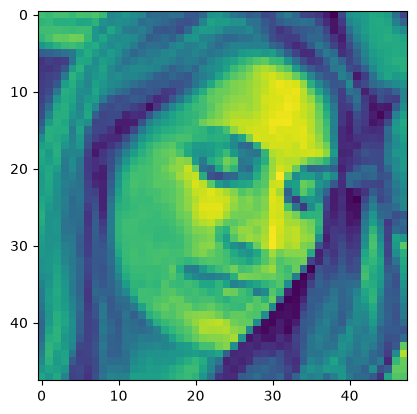

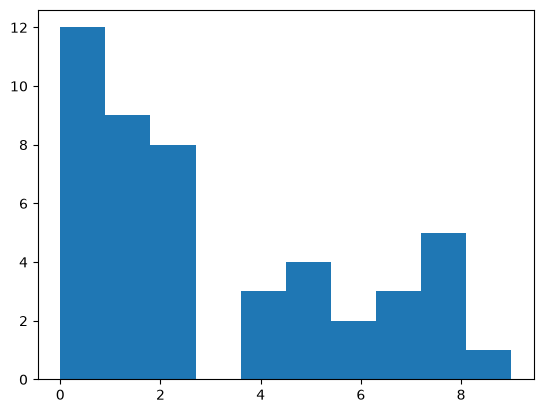

In [19]:
# exemple image with historgramme on one region/16

#category
cat = 3
img_cat = X_test[y_test == cat,:,:]

rand = int(np.floor(np.random.uniform(0,1) * 100))
#take one img
img_test = img_cat[rand,:,:]
plt.imshow(img_test)

#calculate lbp
img_test_lbp = skimage.feature.local_binary_pattern(img_test, 30,6,method='uniform')

#4*4 roi histogramme
N = 4
n_bins = 10
X_test_histNN_counts , X_test_histNN_bins =  NN_histogram(img_test_lbp,N,n_bins)
#X_test_histNN_counts = X_test_histNN_counts.flatten()


region = 10
X_test_histNN_counts_roi = X_test_histNN_counts[region,:]
X_test_histNN_bins_roi = X_test_histNN_bins[region,:]
plt.figure()
plt.hist(X_test_histNN_bins_roi[:-1], X_test_histNN_bins_roi, weights=X_test_histNN_counts_roi)


X_test_histNN_counts = X_test_histNN_counts.flatten()
print(neigh.predict(np.array([X_test_histNN_counts])) == 3)